In [1]:
!pip uninstall -y torchao

In [2]:
!pip install -q -U transformers datasets peft accelerate scikit-learn bitsandbytes

In [3]:
!pip freeze | grep -iE "^(torch|transformers|datasets|peft|accelerate|bitsandbytes|scikit-learn|pandas|numpy)=="

accelerate==1.15.0
bitsandbytes==0.50.2
datasets==5.1.0
numpy==2.1.3
pandas==2.2.3
peft==0.21.2
scikit-learn==1.9.1
torch==2.11.0+cu130
transformers==5.20.2


In [4]:
from datasets import load_dataset, Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding, AutoModelForCausalLM, BitsAndBytesConfig, set_seed
import pandas as pd
import numpy as np
import torch
import random
import matplotlib.pyplot as plt
import seaborn as sns
from peft import LoraConfig, get_peft_model, TaskType
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer as Tfidf
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import gc
import re
import json

pd.set_option("display.max_colwidth", None)


In [5]:
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


In [6]:
SEED = 42
N_CLASSES = 10  #Utilizaremos 10 intenciones
N_MINORITY = 20 #Ejemplos por clase minoritaria
N_MAJORITY_CAP = 400
MODEL_NAME = 'dccuchile/bert-base-spanish-wwm-cased'


## Datos

Descargar el dataset MASSIVE. Son frases que la gente dice a un asistente, clasificadas por intención.

In [7]:
dataset = load_dataset('SetFit/amazon_massive_intent_es-ES')

In [8]:
train_dataset = dataset['train'].to_pandas()
val_dataset = dataset['validation'].to_pandas()
test_dataset = dataset['test'].to_pandas()

In [9]:
train_dataset["label_text"].value_counts()

,count
label_text,
calendar_set,810
play_music,639
weather_query,573
calendar_query,566
general_quirky,555
qa_factoid,544
news_query,503
email_query,418
email_sendemail,354


Vamos a utilizar las 10 intenciones más comunes para este Notebook

In [10]:
lista = train_dataset["label_text"].value_counts().head(N_CLASSES).index.tolist()
print(lista)

train_dataset = train_dataset[train_dataset["label_text"].isin(lista)]
val_dataset = val_dataset[val_dataset["label_text"].isin(lista)]
test_dataset = test_dataset[test_dataset["label_text"].isin(lista)]

['calendar_set', 'play_music', 'weather_query', 'calendar_query', 'general_quirky', 'qa_factoid', 'news_query', 'email_query', 'email_sendemail', 'datetime_query']


Reasignamos las etiquetas del 0 al 9

In [11]:
label2id = {label: i for i, label in enumerate(lista)}
id2label = {i: label for label, i in label2id.items()}

train_dataset["label"] = train_dataset["label_text"].map(label2id)
val_dataset["label"] = val_dataset["label_text"].map(label2id)
test_dataset["label"] = test_dataset["label_text"].map(label2id)

In [12]:
train_dataset.head()

,id,label,text,label_text,label_text_es
21,33,3,mirar cuando empieza el espectáculo,calendar_query,consulta de calendario
22,34,1,quiero escuchar la canción de arijit singh una vez más,play_music,reproducir música
23,35,1,quiero poner esa música una vez mas,play_music,reproducir música
24,36,4,chequea si mi coche está listo,general_quirky,peculiar en general
25,37,4,comprueba si funciona mi portatil,general_quirky,peculiar en general


Vamos a elegir las clases de número de `label` par, de forma que las vamos a elegir como minoritarias, desbalanceando los datos.

Solamente lo hacemos en los datos de entrenamiento porque queremos medir la calidad del modelo con datos reales entrenando con datos desbalanceados.

Escogemos ratio 20:1

In [13]:
minority = random.Random(SEED).sample(list(lista), 4)
print(minority)

['play_music', 'calendar_set', 'general_quirky', 'datetime_query']


In [14]:
parts = []

for lab, g in train_dataset.groupby("label_text"):
  n = N_MINORITY if lab in minority else min(len(g), N_MAJORITY_CAP)
  parts.append(g.sample(n, random_state=SEED))

train_dataset = pd.concat(parts).reset_index(drop=True)

In [15]:
train_dataset["label_text"].value_counts()

,count
label_text,
calendar_query,400
email_query,400
qa_factoid,400
weather_query,400
news_query,400
email_sendemail,354
calendar_set,20
datetime_query,20
general_quirky,20


<Axes: ylabel='label_text'>

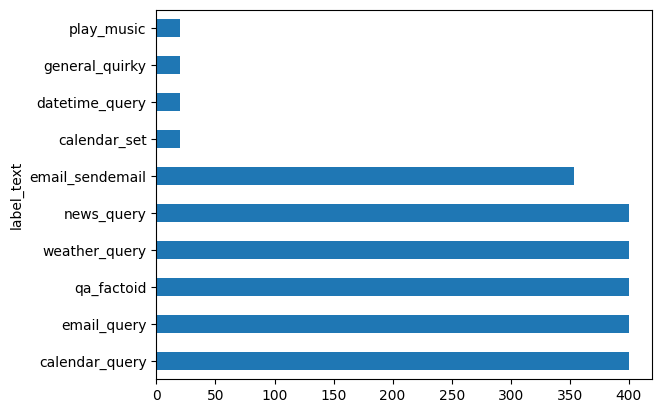

In [16]:
train_dataset["label_text"].value_counts().plot.barh()

Las clases minoritarias son: `play_music`, `general_quirky`, `datetime_query`, `calendar_set`. En estas clases, comprobaremos cuánto podemos mejorar los resultados con data augmentation

## Baseline

Vamos a utilizar TF-IDF como Baseline. Luego, lo compararemos con BETO.

In [17]:
pipeline = make_pipeline(Tfidf(ngram_range=(1,2), sublinear_tf=True), LogisticRegression(max_iter=2000, random_state=SEED))

In [18]:
pipeline.fit(train_dataset["text"], train_dataset["label"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](10,)","[0,1,2,...,7,8,9]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


In [19]:
pred = pipeline.predict(test_dataset["text"])

f1_score(test_dataset["label"], pred, average="macro")

0.44245056409448746

In [20]:
f1_score(test_dataset["label"], pred, average=None)

array([0.        , 0.05524862, 0.84795322, 0.41134752, 0.        ,
       0.5110664 , 0.72025723, 0.84518828, 0.88607595, 0.14736842])

In [21]:
def summarize(nombre, y_true, y_pred):
  """
  Calcula el f1 global, el f1 por clase, accuracy y classification report
  """
  print(f"{nombre}:")
  f1_macro = f1_score(y_true, y_pred, average="macro")
  minority_ids = [label2id[c] for c in minority]
  f1_none = f1_score(y_true, y_pred, average=None)

  mean_minority = np.mean(f1_none[minority_ids])

  acc = accuracy_score(y_true, y_pred)

  print(classification_report(y_true, y_pred, target_names=lista))

  return f1_macro, mean_minority, acc

In [22]:
f1_b, min_b, acc_b = summarize("Baseline", test_dataset["label"], pred)

print(f"F1 macro: {f1_b}")
print(f"F1 minoritarios: {min_b}")
print(f"Accuracy: {acc_b}")

Baseline:
                 precision    recall  f1-score   support

   calendar_set       0.00      0.00      0.00       209
     play_music       1.00      0.03      0.06       176
  weather_query       0.78      0.93      0.85       156
 calendar_query       0.26      0.92      0.41       126
 general_quirky       0.00      0.00      0.00       169
     qa_factoid       0.36      0.90      0.51       141
     news_query       0.60      0.90      0.72       124
    email_query       0.84      0.85      0.85       119
email_sendemail       0.85      0.92      0.89       114
 datetime_query       1.00      0.08      0.15        88

       accuracy                           0.50      1422
      macro avg       0.57      0.55      0.44      1422
   weighted avg       0.52      0.50      0.40      1422

F1 macro: 0.44245056409448746
F1 minoritarios: 0.05065425995929049
Accuracy: 0.5049226441631505


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


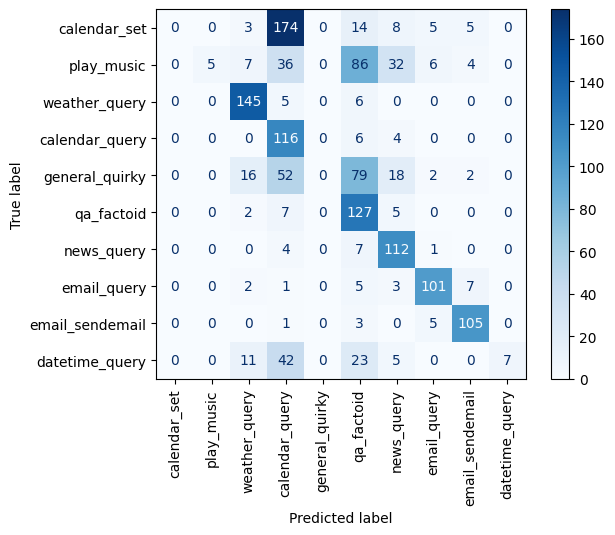

In [23]:
cm = confusion_matrix(test_dataset["label"], pred, labels=list(range(10)))
ConfusionMatrixDisplay(cm, display_labels=lista).plot(xticks_rotation=90, cmap="Blues")
plt.savefig("cm_baseline.png", bbox_inches="tight")

Se observa que las clases minoritarias no se predicen apenas. Las clases mayoritarias que absorben a las minoritarias (como `qa_factoid`)tienen baja precisión también debido a que tienen muchos falsos positivos por este motivo.

Concretamente, `calendar_set` se predice 0 veces, ya que casi todas sus apariciones entran probablemente en `calendar_query`, al ser clases muy parecidas.

`general_quirky` también es una clase complicada para el modelo, con 0 predicciones.

## Fine-tuning a LoRA

In [24]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=N_CLASSES, id2label=id2label, label2id=label2id)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

In [25]:
lens = [len(tokenizer(t)["input_ids"]) for t in train_dataset["text"]]
np.percentile(lens, [95, 99, 100])

array([18., 23., 35.])

Elegimos max_length=32 a artir del percentil 99 de longitud

In [26]:
f = lambda x: tokenizer(x["text"], truncation=True, max_length=32)

In [27]:
val_dataset = Dataset.from_pandas(val_dataset[["text", "label"]]).map(f, batched=True)
test_dataset = Dataset.from_pandas(test_dataset[["text", "label"]]).map(f, batched=True)

Map:   0%|          | 0/959 [00:00<?, ? examples/s]

Map:   0%|          | 0/1422 [00:00<?, ? examples/s]

In [28]:
def compute_metrics(eval_pred):
  logits, labels = eval_pred
  predits = logits.argmax(-1)

  return {
      "f1_macro": f1_score(labels, predits, average="macro")
  }

In [29]:
def train_lora(train_df, run_name):
  set_seed(SEED)
  tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
  model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=N_CLASSES, id2label=id2label, label2id=label2id)
  lora_config = LoraConfig(task_type=TaskType.SEQ_CLS, r=8, lora_alpha=16, lora_dropout=0.1, target_modules=["query", "value"])
  model = get_peft_model(model, lora_config)

  f = lambda x: tokenizer(x["text"], truncation=True, max_length=32)
  train_df = Dataset.from_pandas(train_df[["text", "label"]]).map(f, batched=True)

  args = TrainingArguments(
    output_dir="results",
    learning_rate=5e-4,
    num_train_epochs=15,
    per_device_train_batch_size=64,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    full_determinism=True
  )

  trainer = Trainer(model=model, args=args, train_dataset=train_df, eval_dataset=val_dataset, compute_metrics=compute_metrics, data_collator=DataCollatorWithPadding(tokenizer))

  trainer.train()

  pred = trainer.predict(test_dataset).predictions.argmax(-1)

  f1_macro, mean_minority, acc = summarize(run_name, test_dataset["label"], pred)

  return f1_macro, mean_minority, acc

In [30]:
f1_beto, min_beto, acc_beto = train_lora(train_dataset, "LoRA without data augmentation")

print(f"F1 macro: {f1_beto}")
print(f"F1 minority: {min_beto}")
print(f"Accuracy: {acc_beto}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

Map:   0%|          | 0/2434 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/linear.py:134: UserWarning: Requested unified CUBLASLT workspace size of 1048576 bytes exceeds CUBLAS workspace size of 131072 bytes. Please increase CUBLAS workspace size via CUBLAS_WORKSPACE_CONFIG or decrease requested CUBLASLT_WORKSPACE_SIZE. Otherwise CUBLASLT workspace size will be limited to the CUBLAS workspace size. (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:228.)
  return F.linear(input, self.weight, self.bias)


Epoch,Training Loss,Validation Loss,F1 Macro
1,No log,2.439817,0.343830
2,No log,1.869075,0.422774
3,No log,1.445268,0.475281
4,No log,1.234253,0.546932
5,No log,1.135435,0.574521
6,No log,1.125933,0.601284
7,No log,1.176155,0.623036
8,No log,1.083709,0.648032
9,No log,1.090498,0.660622
10,No log,1.017318,0.694497


LoRA without data augmentation:
                 precision    recall  f1-score   support

   calendar_set       0.95      0.48      0.64       209
     play_music       0.96      0.75      0.84       176
  weather_query       0.83      0.96      0.89       156
 calendar_query       0.42      0.96      0.59       126
 general_quirky       0.86      0.07      0.13       169
     qa_factoid       0.61      0.93      0.74       141
     news_query       0.67      0.94      0.78       124
    email_query       0.90      0.92      0.91       119
email_sendemail       0.85      0.96      0.90       114
 datetime_query       0.98      0.67      0.80        88

       accuracy                           0.73      1422
      macro avg       0.80      0.76      0.72      1422
   weighted avg       0.81      0.73      0.70      1422

F1 macro: 0.7214521076385618
F1 minority: 0.603291289695993
Accuracy: 0.7313642756680732


El modelo mejora bastante los resultados. Podemos observar una gran mejoría en el F1 de las minorías, pasando de 0.05 a 0.60. El resto de métricas también mejoran con respecto a TF-IDF.

**TF-IDF**:
- F1 macro: 0.44
- F1 minoritarios: 0.05
- Accuracy: 0.50

**BETO w/ LoRa without data augmentation**:
- F1 macro: 0.72
- F1 minority: 0.60
- Accuracy: 0.73

Sin embargo, aún hay clases que no se reconocen bien dentro de las minoritarias, como `general_quirky`, con un F1 de 0.13 y recall de 0.07.

## Data Augmentation

Para balancear las clases y mejorar los resultados, realizaremos data augmentation sobre las clases minoritarias, utilizando `Qwen/Qwen2.5-7B-Instruct`

In [31]:
# Liberamos la memoria de BETO para no tener problemas con el nuevo modelo
del model
del tokenizer
gc.collect()
torch.cuda.empty_cache()

In [32]:
DATA_AUG_MODEL = "Qwen/Qwen2.5-7B-Instruct"

In [33]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
)

In [34]:
for label in lista:
  if label in minority:
    continue
  i = 0
  for text in train_dataset[train_dataset["label_text"] == label]["text"]:
    if i < 9:
      print(f"{label}: {text}")
      i += 1


weather_query: cómo está el clima hoy
weather_query: prevision de tiempo
weather_query: como estará el tiempo de valldemossa el nueve de febrero de dos mil diecisiete
weather_query: dime como estará el tiempo la semana que viene en barcelona
weather_query: olly necesito llevar botas
weather_query: hace demasiado calor cómo para llevar mi suéter de lana hoy
weather_query: es probable que haya lluvia en el pronóstico hoy
weather_query: dime si lo siguiente es cierto sobre el tiempo
weather_query: cuál es la probabilidad de lluvia hoy
calendar_query: dime cuándo son mis próximos eventos
calendar_query: tengo un partido el siete de abril
calendar_query: tengo yo una reunión mañana
calendar_query: yo tengo una cita la semana que viene
calendar_query: hay una fiesta de cumpleaños hoy
calendar_query: puedes decirme mis citas de esta semana
calendar_query: dónde es mi reunión de hoy de las doce
calendar_query: que tengo que hacer hoy después de comer
calendar_query: alguna reunión de seis a si

In [35]:
descripciones = {
    "play_music": "Consiste en solicitudes al asistente para reproducir canciones, artistas, géneros, álbumes o listas",
    "calendar_set": "Consiste en peticiones al asistente para crear eventos, recordatorios o avisos en el calendario, con o sin fecha y hora. No son consultas al calendario ni borrados de eventos, solo crear. Escribe las horas y fechas con letras, como ‘a las diez y media’ o ‘el quince de febrero’",
    "general_quirky": "Charla informal con el asistente sin una tarea concreta: preguntas personales al asistente, opiniones, comentarios sueltos o preguntas raras o filosóficas. No son preguntas de datos con respuesta objetiva, ni saludos, ni peticiones de chistes. no pide explicaciones, definiciones ni información (tráfico, tiempo, noticias)",
    "datetime_query": "Preguntas sobre la hora, la fecha o el día, también en otras ciudades o zonas horarias. No son preguntas sobre eventos o citas del calendario"
}

In [36]:
for label in minority:
  for text in train_dataset[train_dataset["label_text"] == label]["text"]:
    print(f"{label}: {text}")

play_music: tocar música de un artista dado
play_music: pon canciones de los del rio
play_music: alexa puedes reproducir mí música favorita
play_music: quiero escuchar a rafael en un concierto en vivo
play_music: por favor retoma mi música
play_music: pon todas las canciones del género blue
play_music: abre canciones de prince
play_music: hoy me apetece hard rock
play_music: pon mi música favorita
play_music: pon algo de música pop
play_music: reproduce mi playlist favorita
play_music: toca surfin u. s. a.
play_music: pon dos mil ciento doce de rush
play_music: pon la siguiente canción en cinco minutos
play_music: empezar a jugar niños por mgmt
play_music: pon mi playlist de rap
play_music: después de esta canción pon metallica
play_music: abrir el reproductor multimedia y reproducir la playlist del gimnasio
play_music: pon mi playlist favorita
play_music: jugar irene de tobymac
calendar_set: envía una notificación a amigo
calendar_set: marca el trece de octubre de este año como mi cum

In [37]:
tokenizer = AutoTokenizer.from_pretrained(DATA_AUG_MODEL)
model = AutoModelForCausalLM.from_pretrained(DATA_AUG_MODEL, quantization_config=bnb_config, device_map="auto")

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

In [38]:
def build_messages(label, examples, n):
  system_message = ("Eres un asistente que me va a ayudar a crear datos sintéticos para el entrenamiento de mi modelo de clasificación de intenciones en mensajes a un asistente virtual."
  "Utiliza SOLO frases en español, una por línea. NO repitas frases. NO des ninguna explicación. NO pongas numeración al principio de las frases.")

  ejemplos_txt = "\n".join(f"- {e}" for e in examples)

  messages = [
    {"role":"system", "content": system_message},
    {"role":"user", "content": f"Escribe {n} frases que un usuario diría a un asistente de voz sobre el tema de {label}. {descripciones[label]}. Aquí hay algunos ejemplos: \n"
    f"{ejemplos_txt} \n Responde SOLO con las 10 frases, una por línea, sin numerar, sin comillas y SIN texto antes ni después"}
  ]

  return messages

In [39]:
label_test = "calendar_set"
messages = build_messages(label_test, random.sample(list(train_dataset[train_dataset['label_text'] == label_test]["text"]), k=5), n=10)

print(messages[1]["content"])

Escribe 10 frases que un usuario diría a un asistente de voz sobre el tema de calendar_set. Consiste en peticiones al asistente para crear eventos, recordatorios o avisos en el calendario, con o sin fecha y hora. No son consultas al calendario ni borrados de eventos, solo crear. Escribe las horas y fechas con letras, como ‘a las diez y media’ o ‘el quince de febrero’. Aquí hay algunos ejemplos: 
- el veintitrés de marzo tengo que ir a encontrarme con mi tía
- envía una notificación a amigo
- añadir evento al calendario
- programa un recordatorio a las tres en punto
- que hugo se una a mí el día diez en la reunión del quinta planta 
 Responde SOLO con las 10 frases, una por línea, sin numerar, sin comillas y SIN texto antes ni después


In [40]:
N_EXAMPLES = 5
N_SYNTHETIC_PHRASES = 10
N_CALLS_PER_LABEL = 15

In [41]:
set_seed(SEED)
rng = random.Random(SEED)

messages_m = {m: [] for m in minority}

for label in minority:
  seen = set(train_dataset[train_dataset['label_text'] == label]["text"])

  print(f"Generating synthetic examples for {label}...")

  for _ in range(N_CALLS_PER_LABEL):
    messages = build_messages(label, rng.sample(list(train_dataset[train_dataset['label_text'] == label]["text"]), k=N_EXAMPLES), n=N_SYNTHETIC_PHRASES)
    messages = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    input = tokenizer(messages, return_tensors="pt").to("cuda" if torch.cuda.is_available() else "cpu")

    output = model.generate(**input, max_new_tokens=400, do_sample=True, temperature=0.9, top_p=0.95)

    n = input["input_ids"].shape[1]
    texto = tokenizer.decode(output[0][n:], skip_special_tokens=True)

    messages = texto.split("\n")

    initial = len(messages)

    messages = [re.sub(r"^\s*([-*•]|\d+[.)])\s*", "", message) for message in messages if message.strip()]

    messages = [re.sub(r"[.,\+\-\$¡!¿?\"\'\:\;\(\))]", " ", message).lower().strip() for message in messages]

    messages = [re.sub(r"\s+", " ", message) for message in messages]

    messages = [message for message in messages if re.match(r"^[a-záéíóúñü ]+$", message)]

    messages = list(set(messages) - seen)

    seen.update(messages)

    messages_m[label].extend(messages)

print(f"Phrases per class: ")
for label in minority:
  print(f"{label}: {len(messages_m[label])}")

Generating synthetic examples for play_music...
Generating synthetic examples for calendar_set...
Generating synthetic examples for general_quirky...
Generating synthetic examples for datetime_query...
Phrases per class: 
play_music: 127
calendar_set: 146
general_quirky: 138
datetime_query: 120


Dejamos 100 ejemplos sintéticos para que BETO no aprenda únicamente lo que se genera con data augmentation, sino que las que ya estaban tengan algo de peso.

In [42]:
train_dataset_augmented = train_dataset.copy()

rows = [{"text": t, "label_text": lab, "label": label2id[lab]} for lab, frases in messages_m.items() for t in frases]

synth_df = pd.DataFrame(rows).groupby("label_text").sample(100, random_state=SEED)

synth_df.to_csv("synthetic_data.csv", index=False)

train_dataset_augmented = pd.concat([train_dataset_augmented, synth_df]).sample(frac=1, random_state=SEED).reset_index(drop=True)


In [43]:
synth_df.groupby("label_text").sample(5, random_state=SEED)

,text,label_text,label
170,programa una reunión semanal de trabajo cada martes,calendar_set,0
196,programa un recordatorio para leer el libro nuevo el sábado por la tarde,calendar_set,0
189,crea un recordatorio para entregar el informe el veinticinco de este mes,calendar_set,0
260,recuérdame de comprar leche y huevos el día once de abril,calendar_set,0
244,crea que suban las cuotas a la asociación el primer viernes de cada mes,calendar_set,0
437,es ya la hora de cenar,datetime_query,9
530,hora en greenwich,datetime_query,9
510,cual es la fecha del día anterior en berlín,datetime_query,9
526,fecha y hora en parís,datetime_query,9
519,que hora es en new york,datetime_query,9


Seleccionando 5 textos aleatorios por clase, vemos que tiene un 95% de frases correctas para su intención.

Hay un fallo: “crea que suban las cuotas a la asociación el primer viernes de cada mes” está mal formada.

In [44]:
train_dataset_augmented["label_text"].value_counts()

,count
label_text,
weather_query,400
calendar_query,400
news_query,400
qa_factoid,400
email_query,400
email_sendemail,354
play_music,120
calendar_set,120
datetime_query,120


In [45]:
f1_aug, min_aug, acc_aug = train_lora(train_dataset_augmented, "LoRA with data augmentation")

print(f"F1 macro: {f1_aug}")
print(f"F1 minority: {min_aug}")
print(f"Accuracy: {acc_aug}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

Map:   0%|          | 0/2834 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,F1 Macro
1,No log,1.483435,0.425130
2,No log,0.843102,0.700346
3,No log,0.663324,0.776780
4,No log,0.672916,0.792818
5,No log,0.735556,0.790118
6,No log,0.665570,0.814045
7,No log,0.713428,0.815438
8,No log,0.719232,0.813833
9,No log,0.745721,0.814507
10,No log,0.714603,0.825935


LoRA with data augmentation:
                 precision    recall  f1-score   support

   calendar_set       0.99      0.70      0.82       209
     play_music       0.98      0.88      0.93       176
  weather_query       0.88      0.97      0.92       156
 calendar_query       0.58      0.92      0.71       126
 general_quirky       0.86      0.41      0.56       169
     qa_factoid       0.72      0.91      0.81       141
     news_query       0.73      0.93      0.82       124
    email_query       0.87      0.92      0.90       119
email_sendemail       0.96      0.95      0.95       114
 datetime_query       0.93      0.93      0.93        88

       accuracy                           0.83      1422
      macro avg       0.85      0.85      0.83      1422
   weighted avg       0.86      0.83      0.83      1422

F1 macro: 0.834453358626827
F1 minority: 0.8094722663153449
Accuracy: 0.8312236286919831


Se observa una gran mejora en los resultados. Llegando a un F1 global de 0.83, F1 en las minorías de 0.80 y accuracy de 0.83

Podemos ver la mejoría sobre todo en las clases con datos sintéticos, las cuales han mejorado sensiblemente su F1, precisión y recall.

In [46]:
results = {
    "tfidf_logreg": {
        "f1_macro": f1_b,
        "f1_minority": min_b,
        "accuracy": acc_b
    },
    "beto_lora": {
        "f1_macro": f1_beto,
        "f1_minority": min_beto,
        "accuracy": acc_beto
    },
    "beto_lora_aug": {
        "f1_macro": f1_aug,
        "f1_minority": min_aug,
        "accuracy": acc_aug
    }
}

In [47]:
with open("results.json", "w") as f:
  json.dump(results, f, indent=2)